In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("../data/train.csv", keep_default_na=False, na_values=["", "NA"])
df.head()

FileNotFoundError: [Errno 2] No such file or directory: '../data/train.csv'

In [ ]:
df.shape

(1460, 81)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

# Data Cleaning

### Missing-handling

In [3]:
missing = df.isnull().sum()

missing_table = pd.DataFrame({"Missing_Count": missing, "Missing_Percentage": (missing / len(df) * 100).round(2)})

missing_table = missing_table[missing_table["Missing_Count"] > 0]
missing_table.sort_values("Missing_Percentage", ascending=False)

NameError: name 'df' is not defined

In [ ]:
none_columns = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]

df[none_columns] = df[none_columns].fillna("None")

In [4]:
missing_table.head ()

NameError: name 'missing_table' is not defined

In [5]:
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(lambda x: x.fillna(x.median()))

NameError: name 'df' is not defined

In [6]:
df["MasVnrType"] = df["MasVnrType"].fillna("None")
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)
df["Alley"] = df["Alley"].fillna("None")

NameError: name 'df' is not defined

In [7]:
bsmt_cols = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "TotalBsmtSF", "BsmtUnfSF", "BsmtFinSF1", "BsmtFinSF2"]
df[df["BsmtQual"].isnull()][bsmt_cols]

NameError: name 'df' is not defined

In [8]:
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(0)
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

NameError: name 'df' is not defined

### Duplicate Check

In [18]:
df.duplicated().sum()

np.int64(0)

### Future Processes

In [19]:
df[df.select_dtypes(include=["string"]).columns] = df.select_dtypes(include=["string"]).astype("object")

In [20]:
df["MSSubClass"] = df["MSSubClass"].astype("object")

In [21]:
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = df.select_dtypes(include=["object"]).columns

### EDA

<Axes: xlabel='SalePrice', ylabel='Count'>

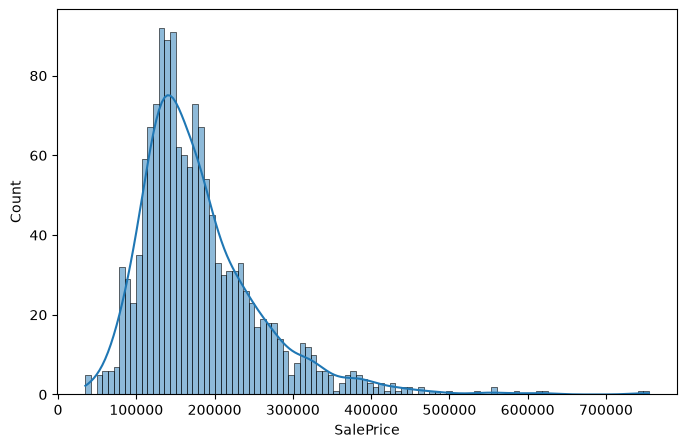

In [22]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="SalePrice", kde=True, bins=100)

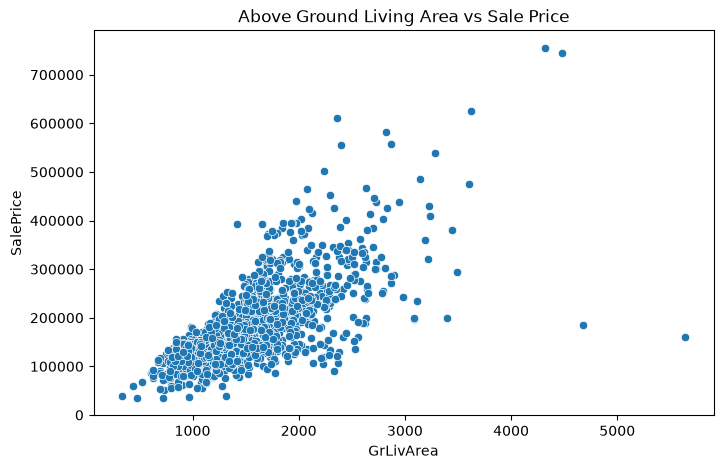

In [23]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice")
plt.title("Above Ground Living Area vs Sale Price")
plt.show()

In [24]:
numeric_features = df.select_dtypes(include=["int64", "float64"]).columns.drop("SalePrice")
outlier_summary = []

for column in numeric_features:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = ((df[column] < lower_bound) | (df[column] > upper_bound)).sum()

    outlier_summary.append({"Feature": column, "Outlier_Count": outlier_count})
outlier_table = pd.DataFrame(outlier_summary)
outlier_table.sort_values("Outlier_Count", ascending=False).head(15)

,Feature,Outlier_Count
29,EnclosedPorch,208
9,BsmtFinSF2,167
4,OverallCond,125
31,ScreenPorch,116
7,MasVnrArea,98
1,LotFrontage,93
17,BsmtHalfBath,82
24,GarageYrBlt,81
28,OpenPorchSF,77
2,LotArea,69


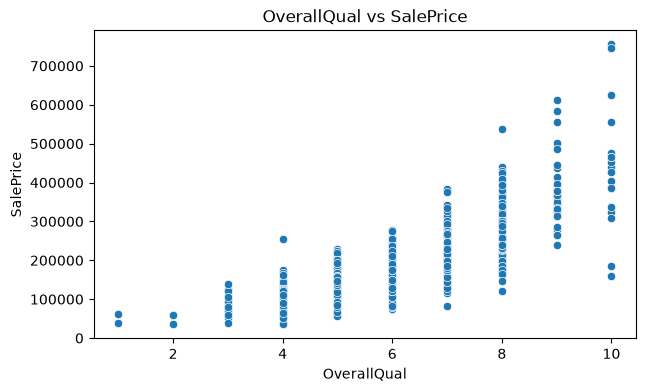

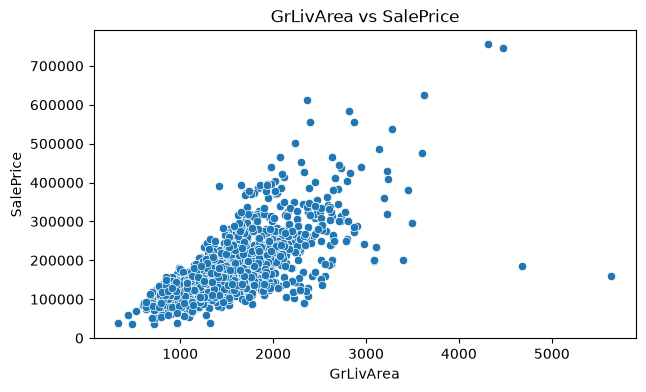

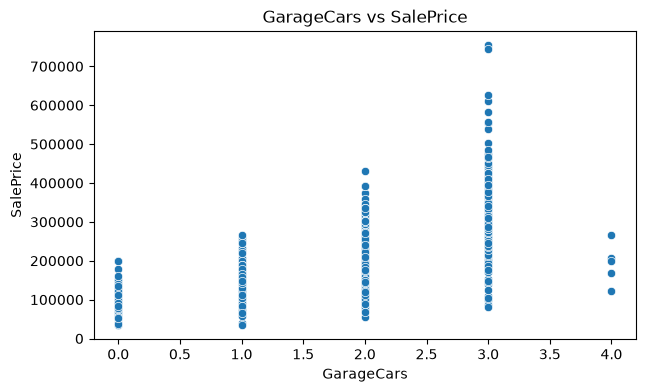

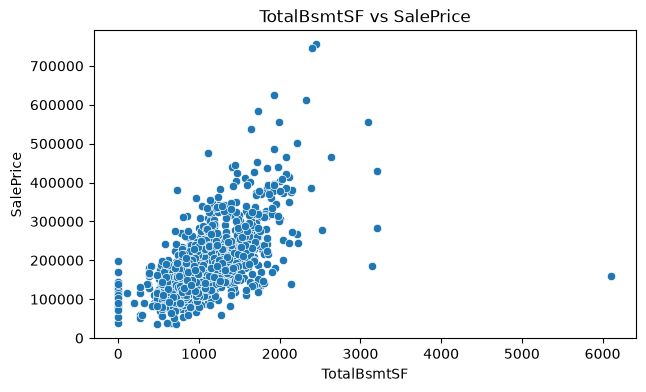

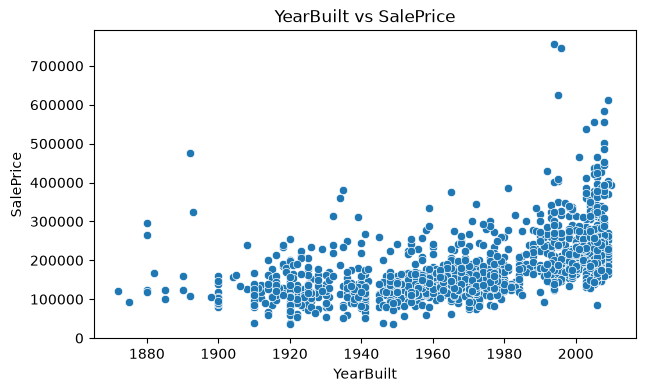

In [25]:
important_features = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "YearBuilt"]

for feature in important_features:
    plt.figure(figsize=(7, 4))
    sns.scatterplot(data=df, x=feature, y="SalePrice")
    plt.title(f"{feature} vs SalePrice")
    plt.show()

### Outlier Handling

In [26]:
potential_outliers = df[(df["GrLivArea"]>4000) & (df["SalePrice"]<300000)] 
potential_outliers[["Id","GrLivArea","SalePrice","OverallQual","YearBuilt","GarageCars","TotalBsmtSF","Neighborhood"]]   

,Id,GrLivArea,SalePrice,OverallQual,YearBuilt,GarageCars,TotalBsmtSF,Neighborhood
523,524,4676,184750,10,2007,3,3138,Edwards
1298,1299,5642,160000,10,2008,2,6110,Edwards


In [27]:
outlier_ids = [524, 1299]
df_model = df[~df["Id"].isin(outlier_ids)].copy()

# Split

In [28]:
print("Original Shape:", df.shape)
print("Model Shape:", df_model.shape)

Original Shape: (1460, 81)
Model Shape: (1458, 81)


In [29]:
df["MSSubClass"] = df["MSSubClass"].astype("object")

In [30]:
X = df_model.drop(columns=["SalePrice", "Id"])
y = df_model["SalePrice"]

In [31]:
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns
print(len(numerical_features))
print(len(categorical_features))

35
44


In [32]:
from sklearn.model_selection import train_test_split
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

# Preprocess Pipeline

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])

categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),
                                          ("encoder", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer(transformers=[("num", numeric_transformer, numerical_features),
                                               ("cat", categorical_transformer, categorical_features)])

# Model Pipeline

In [34]:
from sklearn.dummy import DummyRegressor

baseline_model = Pipeline(steps=[("preprocessor", preprocessor), ("model", DummyRegressor(strategy="mean"))])

baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_valid)

In [35]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

baseline_mae = mean_absolute_error(y_valid, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_valid, baseline_predictions))
baseline_r2 = r2_score(y_valid, baseline_predictions)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R2:", baseline_r2)

Baseline MAE: 57979.83398341127
Baseline RMSE: 74323.78700238478
Baseline R2: -5.394110614864722e-05


after rigde

In [36]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline(steps=[("preprocessor", preprocessor), ("model", Ridge())])

ridge_model.fit(X_train, y_train)
ridge_predictions = ridge_model.predict(X_valid)

print("Ridge MAE:", mean_absolute_error(y_valid, ridge_predictions))
print("Ridge RMSE:", np.sqrt(mean_squared_error(y_valid, ridge_predictions)))
print("Ridge R2:", r2_score(y_valid, ridge_predictions))

Ridge MAE: 17917.22518513962
Ridge RMSE: 24682.471694538977
Ridge R2: 0.8897077336693799


In [37]:
from pathlib import Path
from joblib import dump

models_dir = Path('../models')
models_dir.mkdir(exist_ok=True)

ridge_model.fit(X_train, y_train)
ridge_predictions = ridge_model.predict(X_valid)

ridge_mae = mean_absolute_error(y_valid, ridge_predictions)
ridge_rmse = np.sqrt(mean_squared_error(y_valid, ridge_predictions))
ridge_r2 = r2_score(y_valid, ridge_predictions)

dump(ridge_model, models_dir / 'ridge_model.joblib')

print('Ridge MAE:', ridge_mae)
print('Ridge RMSE:', ridge_rmse)
print('Ridge R2:', ridge_r2)

Ridge MAE: 17917.22518513962
Ridge RMSE: 24682.471694538977
Ridge R2: 0.8897077336693799


Hyperparameter tunning

In [38]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline(steps=[("preprocessor", preprocessor),("model", Ridge())])

ridge_model.fit(X_train, y_train)
ridge_predictions = ridge_model.predict(X_valid)

print("Ridge MAE:", mean_absolute_error(y_valid, ridge_predictions))
print("Ridge RMSE:", np.sqrt(mean_squared_error(y_valid, ridge_predictions)))
print("Ridge R2:", r2_score(y_valid, ridge_predictions))

Ridge MAE: 17917.22518513962
Ridge RMSE: 24682.471694538977
Ridge R2: 0.8897077336693799


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge

ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

param_grid = {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

best_ridge_model = ridge_search.best_estimator_
tuned_predictions = best_ridge_model.predict(X_valid)
tuned_mae = mean_absolute_error(y_valid, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_valid, tuned_predictions))
tuned_r2 = r2_score(y_valid, tuned_predictions)

print("Best alpha:", ridge_search.best_params_)
print("Tuned Ridge MAE:", tuned_mae)
print("Tuned Ridge RMSE:", tuned_rmse)
print("Tuned Ridge R2:", tuned_r2)

dump(best_ridge_model, models_dir / 'best_ridge_model.joblib')

NameError: name 'ridge_search' is not defined